# Analyse de l'activité — Plato's Pizza

Notebook d'exploration SQL + Python : connexion à la base `pizza.db`, requêtes d'analyse commerciale, et premières visualisations avant intégration dans Streamlit.

## 1. Connexion à la base de données

In [1]:
# Connexion à pizza.db (sqlite3 ou SQLAlchemy)
import sqlite3
import pandas as pd 
import matplotlib.pyplot as plt


conn = sqlite3.connect('pizza.db')


## 2. Chiffre d'affaires global et évolution dans le temps

In [2]:
# Requête SQL : CA total, et CA regroupé par mois et par jour de semaine
# Le montant d'une ligne de commande = quantity (order_details) * price (pizzas)
# On relie order_details -> pizzas (pour le prix) -> orders (pour la date)
query = """
SELECT
    strftime('%Y-%m', o.date) AS mois,
    strftime('%w', o.date) AS jour_semaine,
    SUM(od.quantity * p.price) AS ca
FROM order_details od
JOIN pizzas p ON od.pizza_id = p.pizza_id
JOIN orders o ON od.order_id = o.order_id
GROUP BY mois, jour_semaine
ORDER BY mois, jour_semaine;
"""

df_ca = pd.read_sql(query, conn)
df_ca

,mois,jour_semaine,ca
0,2015-01,0,7222.15
1,2015-01,1,8256.55
2,2015-01,2,9404.50
3,2015-01,3,8786.15
4,2015-01,4,12079.00
...,...,...,...
78,2015-12,2,9556.60
79,2015-12,3,10602.55
80,2015-12,4,11163.40
81,2015-12,5,8398.65


### Interprétation

Sur l'année 2015 (seule année couverte par les données), le chiffre d'affaires total s'élève à **817 860 €**.

**Par jour de semaine**, le vendredi (code 5) est le plus rentable (~136 000 €), suivi du jeudi et du samedi, tandis que le dimanche (code 0) est le plus faible (~99 200 €) — l'activité est donc concentrée sur la fin de semaine, logique pour une pizzeria.

**Par mois**, le CA reste assez stable tout au long de l'année (entre 64 000 € et 72 500 € environ), sans saisonnalité marquée — juillet et mai sont légèrement en tête, octobre et septembre un peu en retrait.

**Piste de recommandation :** si la capacité de production est limitée, concentrer le personnel et les stocks sur jeudi-vendredi-samedi serait prioritaire, ces trois jours représentant une part significative du CA hebdomadaire.

## 3. Pizzas les plus / moins vendues

In [3]:
# Requête SQL : top et flop pizzas (quantité et CA)
top_flop = """
SELECT
    pt.name AS pizza_name,
    SUM(od.quantity) AS total_quantity,
    SUM(od.quantity * p.price) AS total_ca
FROM order_details od
JOIN pizzas p ON od.pizza_id = p.pizza_id
JOIN pizza_types pt ON p.pizza_type_id = pt.pizza_type_id
GROUP BY pt.name
ORDER BY total_quantity DESC, total_ca DESC;
"""

df_top_flop = pd.read_sql(top_flop, conn)
df_top_flop

,pizza_name,total_quantity,total_ca
0,The Classic Deluxe Pizza,2453,38180.50
1,The Barbecue Chicken Pizza,2432,42768.00
2,The Hawaiian Pizza,2422,32273.25
3,The Pepperoni Pizza,2418,30161.75
4,The Thai Chicken Pizza,2371,43434.25
5,The California Chicken Pizza,2370,41409.50
6,The Sicilian Pizza,1938,30940.50
7,The Spicy Italian Pizza,1924,34831.25
8,The Southwest Chicken Pizza,1917,34705.75
9,The Big Meat Pizza,1914,22968.00


### Interprétation

**En quantité**, les pizzas Classiques, Barbecue Chicken, Hawaiian, Pepperoni et Thai Chicken se détachent nettement (toutes autour de 2 400 unités vendues), portées surtout par les catégories Classic et Chicken.

**En chiffre d'affaires**, le classement change un peu : The Thai Chicken Pizza (43 434 €) et The Barbecue Chicken Pizza (42 768 €) sont les meilleures ventes en valeur, pas forcément celles vendues en plus grand nombre — ce sont des pizzas à prix plus élevé (catégorie Chicken), donc chaque vente rapporte davantage.

**En bas du classement**, The Brie Carre Pizza se distingue nettement comme la moins vendue (490 unités, 11 589 €), loin derrière toutes les autres — c'est la seule pizza sous les 1 000 unités vendues sur l'année.

**Piste de recommandation :** envisager de retirer ou repositionner The Brie Carre Pizza (fromage de spécialité, probablement un produit de niche), et mettre en avant les pizzas "Chicken" qui génèrent le meilleur CA par unité vendue.

## 4. Performance par catégorie et par taille

In [4]:
# Requête SQL : CA et quantités par category / size

perf_categorie = """
SELECT
    pt.category AS category_name,
    SUM(od.quantity) AS total_quantity,
    SUM(od.quantity * p.price) AS total_ca
FROM order_details od
JOIN pizzas p ON od.pizza_id = p.pizza_id
JOIN pizza_types pt ON p.pizza_type_id = pt.pizza_type_id
GROUP BY pt.category
ORDER BY total_ca DESC;
"""

perf_taille = """
SELECT
    p.size AS size_name,
    SUM(od.quantity) AS total_quantity,
    SUM(od.quantity * p.price) AS total_ca
FROM order_details od
JOIN pizzas p ON od.pizza_id = p.pizza_id
GROUP BY p.size
ORDER BY total_ca DESC;
"""

df_perf_categorie = pd.read_sql(perf_categorie, conn)
df_perf_taille = pd.read_sql(perf_taille, conn)

print(df_perf_categorie)
print("")
print(df_perf_taille)



  category_name  total_quantity   total_ca
0       Classic           14888  220053.10
1       Supreme           11987  208197.00
2       Chicken           11050  195919.50
3        Veggie           11649  193690.45

  size_name  total_quantity   total_ca
0         L           18956  375318.70
1         M           15635  249382.25
2         S           14403  178076.50
3        XL             552   14076.00
4       XXL              28    1006.60


### Interprétation

**Par catégorie**, "Classic" arrive en tête à la fois en quantité (14 888) et en CA (220 053 €), mais l'écart entre les 4 catégories reste modéré — aucune catégorie n'est marginale, Plato's Pizza a un portefeuille de produits équilibré. "Chicken" est la catégorie la moins vendue en quantité, mais génère presque autant de CA que "Veggie" : elle se vend moins mais à un prix unitaire plus élevé (cohérent avec l'observation de la section 3).

**Par taille**, la taille **L** domine très largement (18 956 pizzas vendues, 375 319 € de CA, soit presque la moitié du CA total) devant M et S. Les tailles **XL** et surtout **XXL** sont quasi anecdotiques (respectivement 552 et 28 pizzas vendues sur l'année) — elles existent dans le catalogue mais ne sont presque jamais commandées.

**Piste de recommandation :** la taille L est clairement le format de référence à mettre en avant (dans les menus, les promotions). Les tailles XL/XXL méritent d'être questionnées : les retirer simplifierait la carte sans perte de CA significative, sauf si elles servent une clientèle spécifique (grands groupes) à conserver pour l'image.

## 5. Panier moyen par commande

In [5]:
# Requête SQL : panier moyen, distribution des montants de commande

panier = """
SELECT AVG(montant_commande) AS panier_moyen
FROM (
    SELECT od.order_id, SUM(od.quantity * p.price) AS montant_commande
    FROM order_details od
    JOIN pizzas p ON od.pizza_id = p.pizza_id
    GROUP BY od.order_id
)
"""

df_panier = pd.read_sql(panier, conn)
df_panier



,panier_moyen
0,38.307262


### Interprétation

Le panier moyen est de **38,31 €** par commande. En rapportant ce chiffre au CA total (817 860 €) et au nombre de commandes (21 350), on retrouve une cohérence : 817 860 / 21 350 ≈ 38,31 €, ce qui confirme que le calcul est juste.

Le prix moyen d'une pizza vendue étant d'environ 16,50 € (CA total / quantité totale vendue), un panier à 38,31 € correspond donc en moyenne à **plus de 2 pizzas par commande** — les clients commandent rarement une seule pizza.

**Piste de recommandation :** comme le catalogue actuel ne contient que des pizzas (pas de boissons ni desserts dans les données fournies), l'ajout de produits complémentaires à la carte pourrait être une piste pour augmenter encore le panier moyen — à valider auprès de la direction si ce type de produit existe réellement en magasin mais n'est pas suivi dans cette base.

## 6. Activité par heure / jour (pics d'affluence)

In [6]:
# Requête SQL : nombre de commandes par heure et par jour de semaine
# Table de départ : orders uniquement (pas besoin du prix ici, juste compter les commandes)
# COUNT(DISTINCT order_id) : compte chaque commande une seule fois

activite_heure = """
SELECT
    strftime('%H', time) AS heure,
    COUNT(DISTINCT order_id) AS nb_commandes
FROM orders
GROUP BY heure
ORDER BY nb_commandes DESC;
"""

activite_jour = """
SELECT
    strftime('%w', date) AS jour_semaine,
    COUNT(DISTINCT order_id) AS nb_commandes
FROM orders
GROUP BY jour_semaine
ORDER BY nb_commandes DESC;
"""

df_activite_heure = pd.read_sql(activite_heure, conn)
df_activite_jour = pd.read_sql(activite_jour, conn)

print(df_activite_heure)
print("")
print(df_activite_jour)

   heure  nb_commandes
0     12          2520
1     13          2455
2     18          2399
3     17          2336
4     19          2009
5     16          1920
6     20          1642
7     14          1472
8     15          1468
9     11          1231
10    21          1198
11    22           663
12    23            28
13    10             8
14    09             1

  jour_semaine  nb_commandes
0            5          3538
1            4          3239
2            6          3158
3            3          3024
4            2          2973
5            1          2794
6            0          2624


### Interprétation

**Par heure**, deux pics nets se détachent : le **midi** (12h-13h, environ 2 500 commandes chacune) et le **soir** (17h-19h, entre 2 000 et 2 400 commandes). L'activité est quasi nulle avant 11h et après 22h — logique pour les horaires de service d'une pizzeria.

**Par jour de semaine**, on retrouve le même classement que pour le chiffre d'affaires (section 2) : le vendredi (3 538 commandes) est le jour le plus actif, le dimanche (2 624) le plus calme. L'écart entre le meilleur et le pire jour est d'environ 35 %.

**Piste de recommandation :** renforcer les équipes en cuisine et en livraison sur les créneaux 12h-13h et 17h-19h, en particulier le jeudi, vendredi et samedi — c'est là que se concentre l'essentiel de la charge de travail sur la semaine.

## 7. Visualisations rapides (contrôle visuel avant Streamlit)

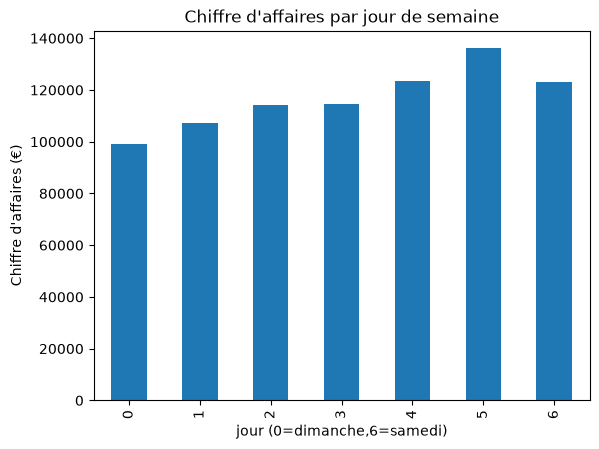

In [7]:
# Graphique 1 : CA par jour de semaine (on réutilise df_ca de la section 2)
ca_par_jour = df_ca.groupby("jour_semaine")["ca"].sum()
ca_par_jour.plot(kind="bar")
plt.title("Chiffre d'affaires par jour de semaine")
plt.xlabel("jour (0=dimanche,6=samedi)")
plt.ylabel("Chiffre d'affaires (€)")
plt.show()

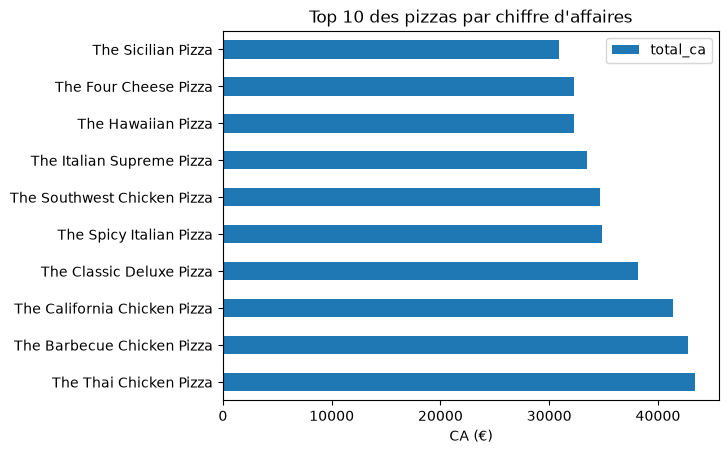

In [8]:
# Graphique 2 — Top 10 pizzas par CA
top10_ca = df_top_flop.sort_values("total_ca", ascending=False).head(10)

top10_ca.plot(x="pizza_name", y="total_ca", kind="barh")
plt.title("Top 10 des pizzas par chiffre d'affaires")
plt.xlabel("CA (€)")
plt.ylabel("")
plt.show()


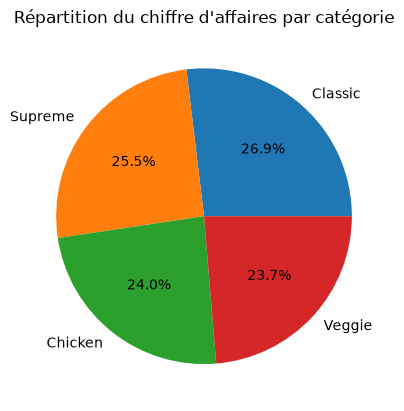

In [9]:
# Graphique 3 — Répartition du CA par catégorie (on réutilise df_perf_categorie de la section 4)
plt.pie(df_perf_categorie["total_ca"], labels=df_perf_categorie["category_name"], autopct="%1.1f%%")
plt.title("Répartition du chiffre d'affaires par catégorie")
plt.show()

## 8. Synthèse des constats et recommandations

## Ce qu'on retient

1. En 2015, Plato's Pizza a fait **817 860 € de CA** sur 21 350 commandes, soit environ 38 € par commande (à peu près 2 pizzas).
2. Les jours les plus chargés sont **jeudi, vendredi, samedi**, et dans la journée ça se joue surtout **entre 12h-13h et 17h-19h**.
3. La taille **L** est largement la plus vendue (presque la moitié du CA vient d'elle).
4. Les 4 catégories de pizzas (Classic, Supreme, Chicken, Veggie) se vendent toutes à peu près pareil, pas de grosse différence.
5. The Thai Chicken et The Barbecue Chicken rapportent le plus. The Brie Carre est clairement la moins vendue, loin derrière toutes les autres.

## Ce qu'on pourrait proposer

- Mettre plus de monde en cuisine/livraison sur les créneaux et jours identifiés ci-dessus, pour ne pas être débordé.
- Mettre en avant la taille L et les pizzas Chicken (ce sont elles qui rapportent le plus).
- Se poser la question de garder ou non la pizza Brie Carre et les tailles XL/XXL, qui se vendent très peu.
- Voir si on peut vendre autre chose à côté des pizzas (boisson, dessert) pour faire monter le panier moyen.

## Limites

- On n'a qu'une seule année de données (2015), donc impossible de dire si c'est pareil chaque année.
- Il n'y a que des pizzas dans les données, pas de boissons ni desserts.
- On n'a aucune info sur les clients eux-mêmes (qui ils sont, où ils habitent), donc on ne peut pas aller plus loin dans ce sens.